In [1]:
import pandas as pd
from datetime import datetime
import chardet
import pandas as pd
from haversine import haversine
import numpy as np
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import pandas as pd
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [2]:


df = pd.read_csv("seoul_with_address.csv")

def extract_city_gu_dong(addr):
    city, gu, dong = "", "", ""
    if pd.isna(addr):
        return city, gu, dong

    # 주소 문자열을 콤마로 분리
    parts = [p.strip() for p in addr.split(',')]

    for p in parts:
        if p.endswith('시'):
            city = p
        elif p.endswith('구'):
            gu = p
        elif p.endswith('동'):
            dong = p

    return city, gu, dong


df[['city', 'gu', 'dong']] = df['address'].apply(lambda x: pd.Series(extract_city_gu_dong(x)))

df.to_csv("seoul_with_city_gu_dong.csv", index=False, encoding='utf-8-sig')

print(df[['address', 'city', 'gu', 'dong']].head())


                                             address   city   gu  dong
0        동방미주아파트, 동일로, 상계1동, 노원구, 서울특별시, 01604, 대한민국  서울특별시  노원구  상계1동
1  수락파크빌아파트, 동일로248가길, 수락파크빌아파트, 상계1동, 노원구, 서울특별시...  서울특별시  노원구  상계1동
2                      상계1동, 노원구, 서울특별시, 01604, 대한민국  서울특별시  노원구  상계1동
3                      상계1동, 노원구, 서울특별시, 01631, 대한민국  서울특별시  노원구  상계1동
4            동일로242라길, 상계1동, 노원구, 서울특별시, 01631, 대한민국  서울특별시  노원구  상계1동


In [3]:




print("📂 데이터 미리보기:")
print(df.head(3))
print()

# YYYYMM → datetime
df['buildDate'] = df['buildDate'].astype(str).str.zfill(6)  # '200006' 형태 유지
df['buildDate_dt'] = pd.to_datetime(df['buildDate'], format='%Y%m', errors='coerce')

# 현재 날짜 기준 (2025년 11월)
current = pd.Timestamp(year=2025, month=11, day=1)

# 경과 개월 / 년 계산
df['elapsed_months'] = (current.year - df['buildDate_dt'].dt.year) * 12 + \
                       (current.month - df['buildDate_dt'].dt.month)
df['elapsed_years'] = df['elapsed_months'] / 12

#건축경과년으로 대체
df['buildDate'] = df['elapsed_years']

# 중간 계산 열 제거
df = df.drop(columns=['id','min_sales','max_sales','buildDate_dt', 'elapsed_months', 'elapsed_years'], errors='ignore')


print("변환 완료")
print(df[['buildDate']].head())

df.to_csv("House.csv", index=False, encoding='utf-8-sig')
print("\n💾 저장 완료 → House_data_updated.csv")


📂 데이터 미리보기:
      id        lat         lng  households  buildDate  score   m2   p  \
0   2766  37.681604  127.056592         492     200006    4.3  139  42   
1   5860  37.679290  127.057021         468     200105    4.1  105  32   
2  15564  37.676882  127.058075          57     200502    4.8   86  26   

   min_sales  max_sales  avg_sales  \
0    60100.0    62000.0    61000.0   
1    48600.0    52200.0    51000.0   
2    36000.0    46000.0    40500.0   

                                             address   city   gu  dong  
0        동방미주아파트, 동일로, 상계1동, 노원구, 서울특별시, 01604, 대한민국  서울특별시  노원구  상계1동  
1  수락파크빌아파트, 동일로248가길, 수락파크빌아파트, 상계1동, 노원구, 서울특별시...  서울특별시  노원구  상계1동  
2                      상계1동, 노원구, 서울특별시, 01604, 대한민국  서울특별시  노원구  상계1동  

변환 완료
   buildDate
0  25.416667
1  24.500000
2  20.750000
3  30.166667
4  22.416667

💾 저장 완료 → House_data_updated.csv


<h1>여기까지가 시각화 전 데이터 전처리<h1>
<h1>여기서부터 1차 모델에 넣을 데이터 전처리<h1>

In [4]:


missing_gu = df['gu'].isna() | (df['gu'].astype(str).str.strip() == "")

df.loc[missing_gu, 'gu'] = df.loc[missing_gu, 'city']


In [5]:
df = df.dropna(subset=['avg_sales'])
df = df.drop(columns=['p'])

In [6]:
drop_gus = ['구리시', '광명시', '의정부시','대구광역시']
df = df[~df['city'].isin(drop_gus)].reset_index(drop=True)

In [7]:
df.isnull().sum()

lat           0
lng           0
households    0
buildDate     0
score         0
m2            0
avg_sales     0
address       0
city          0
gu            0
dong          0
dtype: int64

In [8]:
df

,lat,lng,households,buildDate,score,m2,avg_sales,address,city,gu,dong
0,37.681604,127.056592,492,25.416667,4.3,139,61000.0,"동방미주아파트, 동일로, 상계1동, 노원구, 서울특별시, 01604, 대한민국",서울특별시,노원구,상계1동
1,37.679290,127.057021,468,24.500000,4.1,105,51000.0,"수락파크빌아파트, 동일로248가길, 수락파크빌아파트, 상계1동, 노원구, 서울특별시...",서울특별시,노원구,상계1동
2,37.676882,127.058075,57,20.750000,4.8,86,40500.0,"상계1동, 노원구, 서울특별시, 01604, 대한민국",서울특별시,노원구,상계1동
3,37.675277,127.060001,216,30.166667,4.8,102,34500.0,"상계1동, 노원구, 서울특별시, 01631, 대한민국",서울특별시,노원구,상계1동
4,37.676381,127.058361,165,22.416667,4.8,91,40000.0,"동일로242라길, 상계1동, 노원구, 서울특별시, 01631, 대한민국",서울특별시,노원구,상계1동
...,...,...,...,...,...,...,...,...,...,...,...
3654,37.532183,126.866836,392,22.416667,4.5,86,63000.0,"목동중앙서로10길, 목4동, 양천구, 서울특별시, 07967, 대한민국",서울특별시,양천구,목4동
3655,37.531725,126.829592,120,16.833333,4.0,106,20000.0,"남부순환로56가길, 신월3동, 양천구, 서울특별시, 14406, 대한민국",서울특별시,양천구,신월3동
3656,37.531586,126.828611,92,15.750000,3.5,83,24000.0,"남부순환로56길, 신월3동, 양천구, 서울특별시, 14406, 대한민국",서울특별시,양천구,신월3동
3657,37.530969,126.867097,119,22.416667,4.3,75,70000.0,"목동중앙서로10길, 목4동, 양천구, 서울특별시, 07966, 대한민국",서울특별시,양천구,목4동


In [9]:
df.to_csv("BaseData.csv", index=False, encoding='utf-8-sig')

<h1>여기서부터 2차 모델에 넣을 변수 추가<h1>
<h1>공공시설은 따로 받아옴<h1>

In [10]:


houses = pd.read_csv("편의시설.csv")

stations = pd.read_csv("서울시 역사마스터 정보.csv", encoding="cp949")

station_lat_col = 'lat'   
station_lng_col = 'lng'   

# 가장 가까운 지하철역 거리 계산
def nearest_subway_dist(h_lat, h_lng):
    house_xy = (h_lat, h_lng)
    
    
    dists = stations.apply(
        lambda row: haversine(
            house_xy, 
            (row[station_lat_col], row[station_lng_col])
        ), 
        axis=1
    )
    return dists.min() 

# 4) 집 → 지하철역 최소거리 계산
houses["subway_nearest_km"] = houses.apply(
    lambda row: nearest_subway_dist(row["lat"], row["lng"]),
    axis=1
)

print("🎉 지하철 최소거리 계산 완료!")
print(houses[['lat','lng','subway_nearest_km']].head())


🎉 지하철 최소거리 계산 완료!
         lat         lng  subway_nearest_km
0  37.681604  127.056592           0.432253
1  37.679290  127.057021           0.219465
2  37.676882  127.058075           0.265710
3  37.675277  127.060001           0.501928
4  37.676381  127.058361           0.313898


In [11]:
df = houses

# =========================================
# 자치구별 가구증가율 붙이기
# =========================================

growth = pd.read_csv("2021_총가구증가율.csv")   # 필요하면 encoding='cp949' 옵션 추가


# 컬럼 이름 정리
growth = growth.rename(columns={
    'Category': 'gu',
    '서울특별시': 'household_growth_2021'   # 자치구별 총가구 증가율 (%)
})

#공백 제거
growth['gu'] = growth['gu'].str.strip()

df['gu'] = df['gu'].astype(str).str.strip()

# 머지
df = df.merge(growth[['gu', 'household_growth_2021']],
              on='gu', how='left')

# =========================================
# 자치구별 아파트 거래수 붙이기
# =========================================
apt = pd.read_csv("아파트매매거래+현황_20251130155056.csv")  

apt_clean = apt.iloc[1:].copy()

apt_clean = apt_clean[apt_clean['자치구별(1)'] == '합계'].copy()

# gu 이름 컬럼으로 재정의
apt_clean = apt_clean.rename(columns={
    '자치구별(2)': 'gu',
    '2021': 'apt_transactions_2021'   # 2021년 아파트 매매 거래수
})

# 공백 제거
apt_clean['gu'] = apt_clean['gu'].astype(str).str.strip()

apt_clean['apt_transactions_2021'] = pd.to_numeric(
    apt_clean['apt_transactions_2021'], errors='coerce'
)

# 필요한 컬럼만 남기기
apt_clean = apt_clean[['gu', 'apt_transactions_2021']]

# 메인 df에 머지
df = df.merge(apt_clean, on='gu', how='left')

# =========================================
# 결과 저장
# =========================================

print("✅ 병합 완료!")
print(df[['gu', 'household_growth_2021', 'apt_transactions_2021']].head())


✅ 병합 완료!
    gu  household_growth_2021  apt_transactions_2021
0  노원구                   0.85                   4434
1  노원구                   0.85                   4434
2  노원구                   0.85                   4434
3  노원구                   0.85                   4434
4  노원구                   0.85                   4434


In [12]:
dong_target_mean = df.groupby('dong')['avg_sales'].mean()
df['dong_te'] = df['dong'].map(dong_target_mean)


In [13]:
df.head(1)

,lat,lng,households,buildDate,score,m2,avg_sales,address,city,gu,dong,school_total,subway_total,public_total,hospital_total,mart_total,subway_nearest_km,household_growth_2021,apt_transactions_2021,dong_te
0,37.681604,127.056592,492,25.416667,4.3,139,61000.0,"동방미주아파트, 동일로, 상계1동, 노원구, 서울특별시, 01604, 대한민국",서울특별시,노원구,상계1동,8,1,6,49,0,0.432253,0.85,4434,34283.333333


In [14]:
df.to_csv("useData.csv", index=False, encoding="utf-8-sig")

In [15]:

df = pd.read_csv('useData.csv')
drop_df = df.drop(['lat','lng','address','city','gu','dong'], axis=1, inplace = False)
drop_df

# 1) 숫자형만 남기기
X_vif = drop_df.select_dtypes(include=[np.number]).copy()

# 2) inf → NaN
X_vif = X_vif.replace([np.inf, -np.inf], np.nan)

# 3) NaN 제거
X_vif = X_vif.dropna()

In [16]:

X = X_vif  # 수치형 변수만 넣기
X = add_constant(X)

vif = pd.DataFrame()
vif["feature"] = X.columns
vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

print(vif)

                  feature        VIF
0                   const  60.009418
1              households   1.124891
2               buildDate   1.271735
3                   score   1.091993
4                      m2   1.659451
5               avg_sales   3.447532
6            school_total   1.148214
7            subway_total   1.712507
8            public_total   1.384240
9          hospital_total   1.482477
10             mart_total   1.162473
11      subway_nearest_km   1.457274
12  household_growth_2021   1.180327
13  apt_transactions_2021   1.311095
14                dong_te   2.539837


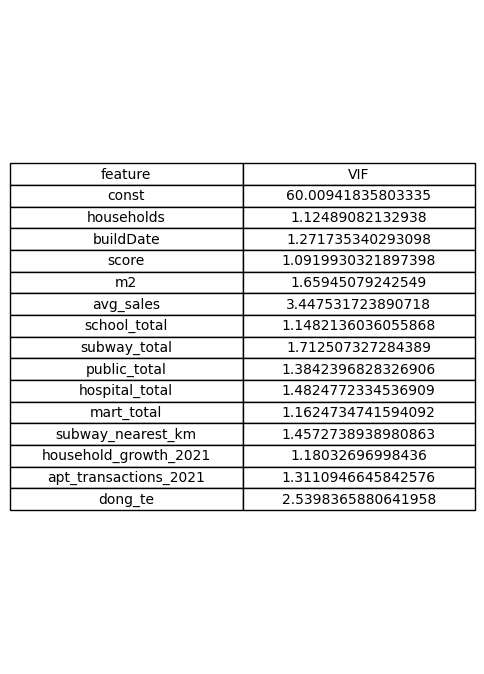

In [17]:

fig, ax = plt.subplots(figsize=(6, len(vif)*0.5 + 1))
ax.axis('off')

table = ax.table(
    cellText=vif.values,
    colLabels=vif.columns,
    cellLoc='center',
    loc='center'
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.3)

plt.savefig("vif_table.png", dpi=300, bbox_inches='tight')
plt.show()


In [18]:
df.head(1)

,lat,lng,households,buildDate,score,m2,avg_sales,address,city,gu,dong,school_total,subway_total,public_total,hospital_total,mart_total,subway_nearest_km,household_growth_2021,apt_transactions_2021,dong_te
0,37.681604,127.056592,492,25.416667,4.3,139,61000.0,"동방미주아파트, 동일로, 상계1동, 노원구, 서울특별시, 01604, 대한민국",서울특별시,노원구,상계1동,8,1,6,49,0,0.432253,0.85,4434,34283.333333


In [19]:
df.isnull().sum()

lat                      0
lng                      0
households               0
buildDate                0
score                    0
m2                       0
avg_sales                0
address                  0
city                     4
gu                       0
dong                     4
school_total             0
subway_total             0
public_total             0
hospital_total           0
mart_total               0
subway_nearest_km        0
household_growth_2021    0
apt_transactions_2021    0
dong_te                  4
dtype: int64

city
서울특별시    3655
Name: count, dtype: int64


C:\Users\hyper\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49436 (\N{HANGUL SYLLABLE SEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\hyper\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 50872 (\N{HANGUL SYLLABLE UL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\hyper\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 53945 (\N{HANGUL SYLLABLE TEUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\hyper\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\hyper\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 4

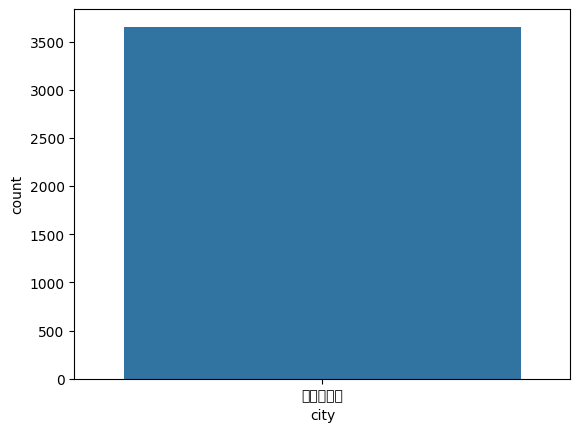

In [20]:
print(df['city'].value_counts())
sns.countplot(x = 'city', data = df)
plt.show()

In [21]:
df = pd.read_csv('useData결측치수정.csv')
df.isnull().sum()

lat                      0
lng                      0
households               0
buildDate                0
score                    0
m2                       0
avg_sales                0
address                  0
city                     0
gu                       0
dong                     0
school_total             0
subway_total             0
public_total             0
hospital_total           0
mart_total               0
subway_nearest_km        0
household_growth_2021    0
apt_transactions_2021    0
dong_te                  0
dtype: int64

In [22]:
df.to_csv("useData.csv", index=False, encoding="utf-8-sig")
df.isnull().sum()

lat                      0
lng                      0
households               0
buildDate                0
score                    0
m2                       0
avg_sales                0
address                  0
city                     0
gu                       0
dong                     0
school_total             0
subway_total             0
public_total             0
hospital_total           0
mart_total               0
subway_nearest_km        0
household_growth_2021    0
apt_transactions_2021    0
dong_te                  0
dtype: int64